# Inférence avec l'early fusion

Ce notebook prédit la classe d'un plat à partir d'une **image** et de son **titre**, avec le modèle
**early fusion** (Table IV de l'article : features InceptionV3 + features BERT/LSTM → MLP).

Deux façons de lui donner des données :

- **A. Des échantillons du test**, déjà sur Modal : tu donnes leurs noms de fichier, ou tu en tires
  au hasard. On connaît leur vraie classe, donc on voit si le modèle a raison.
- **B. Tes propres images**, depuis ton ordinateur, avec un titre que tu écris.

**Comment ça marche** : les modèles et leurs poids sont sur Modal (volume `food101-ckpt`). Chaque
prédiction démarre un petit conteneur, charge les modèles et renvoie le résultat : compte
**1 à 2 minutes** par exécution, quel que soit le nombre d'images.

**Avant de commencer** : choisis le noyau du venv **`food101`** (en haut à droite du notebook), c'est
celui qui a `modal`.

## 1. Préparation

Cette cellule connecte le notebook au projet et définit `show`, qui affiche les résultats :
une image par colonne, avec en dessous son titre, sa vraie classe (si on la connaît) et les
prédictions des trois modèles. **Vert** = juste, **rouge** = faux, gris = vraie classe inconnue.
Le nombre entre parenthèses est la probabilité donnée par le modèle.

Tu n'as rien à modifier ici.

In [1]:
import io
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import modal
from PIL import Image

ROOT = Path("..").resolve()                   # project root, seen from notebooks/
sys.path.insert(0, str(ROOT))
from modal_app import app, predict_samples, predict_test_samples

MODEL = "early"                               # fusion run to use (folder /ckpt/early)
TOP_K = 3                                     # how many classes to list for the fusion


def show(images: list[bytes], result: dict, true_classes: list[str | None]) -> None:
    # One column per sample: image, then title, true class and each model's top-1 prediction.
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(4.5 * n, 7), squeeze=False)
    for ax, image, pred, true in zip(axes[0], images, result["predictions"], true_classes):
        ax.imshow(Image.open(io.BytesIO(image)).convert("RGB"))
        ax.axis("off")
        lines = [textwrap.shorten(pred["title"] or "(pas de titre)", 45),
                 f"vraie classe : {true or '?'}"]
        colors = ["black", "black"]
        for model_name, label in (("image", "image seule"), ("text", "texte seul"), ("fusion", "FUSION")):
            name, prob = pred[model_name][0]
            lines.append(f"{label} : {name} ({prob:.2f})")
            colors.append("gray" if true is None else ("green" if name == true else "red"))
        for i, (line, color) in enumerate(zip(lines, colors)):
            ax.text(0.5, -0.05 - 0.085 * i, line, transform=ax.transAxes, ha="center", va="top",
                    fontsize=10, color=color, fontweight="bold" if line.startswith("FUSION") else None)
    fig.suptitle(f"modèle : {result['model']}  (accuracy val {result['val_acc']:.1%}, "
                 f"test {result['test_acc']:.1%})", fontsize=12)
    fig.subplots_adjust(bottom=0.4, top=0.92, wspace=0.3)
    plt.show()
    for pred in result["predictions"]:                 # full top-k of the fusion, as text
        print(f"{pred['title'][:60]!r:<64} fusion top-{TOP_K}: "
              + ", ".join(f"{name} ({prob:.2f})" for name, prob in pred["fusion"]))

## 2. Option A : échantillons du test (sur Modal)

- Pour choisir des images précises, mets leurs noms dans `SAMPLE_IDS`, par exemple
  `["pizza_12.jpg", "sushi_85.jpg"]` (les noms sont de la forme `<classe>_<numéro>.jpg`, voir
  `results/early_test_predictions.csv`).
- Si `SAMPLE_IDS` est vide, `N_RANDOM` images sont tirées au hasard dans le test. Change `SEED` pour
  avoir un autre tirage (même `SEED` = mêmes images).

✓ Initialized. View run at 
https://modal.com/apps/zaynabezzahraouy/main/ap-87Ny92UBQbFMkFcVKeUbFz
⠋ Initializing...
⠸ Creating objects...objects...
├── ⠋
├── ⠋
⠦ Creating objects...
├── ✓ Uploaded /Users/zaynabez-zahraouy/Desktop/Advanced_deep_learning/project 
│   1/codev1/modal_app.py
├── ✓ Uploaded /Users/zaynabez-zahraouy/Desktop/Advanced_deep_learning/project 
│   1/codev1/configs
⠏ Creating objects... of 11 files
├── ✓ Uploaded /Users/zaynabez-zahraouy/Desktop/Advanced_deep_learning/project 
│   1/codev1/modal_app.py
├── ✓ Uploaded /Users/zaynabez-zahraouy/Desktop/Advanced_deep_learning/project 
│   1/codev1/configs
├── ✓ Uploaded PythonPackage:src
├── ✓ Created Function check_env.
├── ✓ Created Function download_data.
├── ✓ Created Function inspect_data.
├── ✓ Created Function split_data.
├── ✓ Created Function test_data.
├── ✓ Created Function test_image_model.
├── ✓ Created Function test_train.
├── ⠋ Creating Function train_image...
├── ⠋ Creating Function train_text...
├── ✓

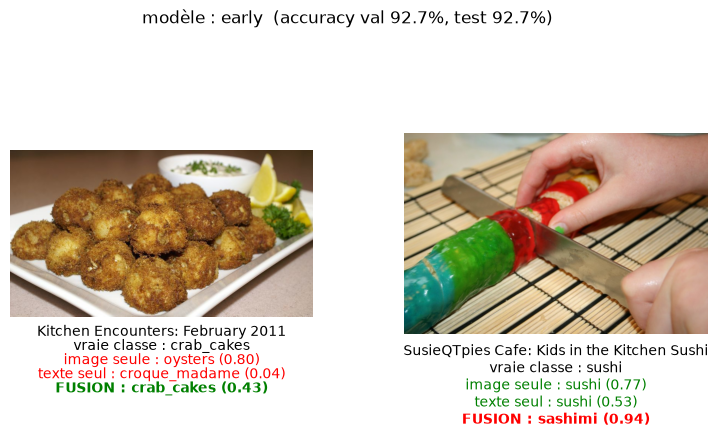

'Kitchen Encounters: February 2011'                              fusion top-3: crab_cakes (0.43), oysters (0.13), macarons (0.06)
'SusieQTpies Cafe: Kids in the Kitchen Sushi'                    fusion top-3: sashimi (0.94), sushi (0.05), seaweed_salad (0.00)


In [3]:
SAMPLE_IDS = ["crab_cakes_391.jpg", "sushi_85.jpg"]          # e.g. ["crab_cakes_391.jpg", "sushi_85.jpg"]; empty = random draw
N_RANDOM = 4
SEED = 0

with modal.enable_output(), app.run():
    result = predict_test_samples.remote(SAMPLE_IDS, N_RANDOM, SEED, TOP_K, MODEL)

samples = result["samples"]
show([s["image"] for s in samples], result, [s["true"] for s in samples])

## 3. Option B : tes propres images

- Ajoute un couple `(chemin de l'image, titre)` par image dans `MY_SAMPLES`. Le titre joue le rôle du
  titre de la page web : un nom de recette, un titre de blog... Le modèle texte a appris sur des
  titres en anglais.
- Mets la vraie classe dans `MY_TRUE_CLASSES` si tu la connais (même ordre, `None` sinon) : ça colore
  les prédictions en vert / rouge. Les 101 noms de classes sont ceux des dossiers, par exemple
  `pizza`, `sushi`, `apple_pie`.
- Formats acceptés : JPEG, PNG... (tout ce que PIL sait ouvrir).
- **Exemple fourni** : si `MY_SAMPLES` est vide, la cellule prend une image de takoyaki de
  `results/examples/` avec deux titres : un titre correct, et un titre trompeur qui parle de pizza.
  Ça montre ce que fait la fusion quand l'image et le texte se contredisent.

In [ ]:
MY_SAMPLES = [           # (image path, title), e.g. ("/Users/me/Pictures/pizza.jpg", "Homemade margherita pizza")
]
MY_TRUE_CLASSES = []     # same order, e.g. ["pizza"]; leave empty if unknown

if not MY_SAMPLES:       # demo: the same image with two different titles
    demo = ROOT / "results" / "examples" / "b_text_wrong_fusion_right" / "takoyaki_245.jpg"
    MY_SAMPLES = [(demo, "Takoyaki recipe: Japanese octopus balls"), (demo, "The best pizza in town")]
    MY_TRUE_CLASSES = ["takoyaki", "takoyaki"]

images = [Path(path).expanduser().read_bytes() for path, _ in MY_SAMPLES]
titles = [title for _, title in MY_SAMPLES]
true_classes = MY_TRUE_CLASSES or [None] * len(MY_SAMPLES)

with modal.enable_output(), app.run():
    result = predict_samples.remote(images, titles, TOP_K, MODEL)

show(images, result, true_classes)

## Comment lire les résultats

- **image seule** et **texte seul** : les deux modèles de base (InceptionV3, BERT + LSTM), chacun avec
  une seule source d'information.
- **FUSION** : l'early fusion, qui combine les features des deux. Sur le test, elle a raison 92,7 %
  du temps, contre 72,2 % pour l'image seule et 85,4 % pour le texte seul.
- Quand l'image et le texte se contredisent, regarde les probabilités : un titre vague
  ("Easy recipes", "Kitchen Encounters: February 2011") laisse en général l'image décider, alors
  qu'un titre qui nomme un plat pèse beaucoup, même s'il est faux (essaie l'exemple de l'option B).
- Une probabilité faible (< 0,5) veut dire que le modèle hésite : regarde alors le top-3 imprimé
  sous la figure.